# GLD965 MA5 multi-horizon v2.1

One chronological 70/30 train/test split before the last two Bangkok calendar months, followed by OOT. Five direct horizons (15–75 minutes), residual regression and MA5 direction classification. Run `experiment.py` for model retraining.

In [1]:
from pathlib import Path
import pandas as pd
from IPython.display import display, Image
P=Path.cwd()
display(pd.read_csv(P/'Methodology.csv'))
display(pd.read_csv(P/'Schedule.csv'))

,item,value
0,source,/workspace/tidewatch_wiki/research/mts_gold/tr...
1,source_sha256,32a54a7ea2346de99359c7347cd6f184ea3af23b828250...
2,oot_start_rule,Latest saved decision time minus two Bangkok c...
3,oot_cutoff,2026-09-06 22:00:00+00:00
4,split,"70%/30% of pre-OOT common eligible rows, chron..."
5,target,"Next trailing MA5 at h=1..5, all common rows h..."
6,regression,Predict normalized residual (Y-structural)/cur...
7,classification,"1 if future MA5>current observed MA5, else 0; ..."
8,feature_gate,At least 3 features with each >=5% of LightGBM...
9,model,Fixed v2 hyperparameters; no model selection o...


,partition,rows,first,last,first_label_h5,last_label_h5
0,TRAIN,24194,2024-12-31 18:15:00+00:00,2026-03-06 09:30:00+00:00,2024-12-31 19:30:00+00:00,2026-03-06 10:45:00+00:00
1,TEST,10372,2026-03-06 11:00:00+00:00,2026-09-04 19:45:00+00:00,2026-03-06 12:15:00+00:00,2026-09-04 21:00:00+00:00
2,OOT,3629,2026-09-07 00:30:00+00:00,2026-11-06 20:45:00+00:00,2026-09-07 01:45:00+00:00,2026-11-06 22:00:00+00:00


In [2]:
q=pd.read_csv(P/'Feature_quality.csv');g=pd.read_csv(P/'Feature_gain.csv');display(q.groupby('selected').size().rename('features'));display(g.groupby(['horizon','task']).over_5pct.sum().unstack())

selected
False    10
True     36
Name: features, dtype: int64

task,classification,regression
horizon,,
1,3,4
2,3,4
3,2,5
4,2,11
5,2,9


In [3]:
m=pd.read_csv(P/'Metrics.csv');display(m[['partition','horizon','task','model','RMSE','MAE','accuracy','balanced_accuracy','MCC','features_ge_5pct','gain_gate_ge3']])

,partition,horizon,task,model,RMSE,MAE,accuracy,balanced_accuracy,MCC,features_ge_5pct,gain_gate_ge3
0,TRAIN,1,regression,Structural,16.196768,8.928883,0.840126,0.839445,0.678774,NaN,NaN
1,TEST,1,regression,Structural,20.238283,13.335037,0.848727,0.848685,0.697399,NaN,NaN
2,OOT,1,regression,Structural,14.665393,10.556737,0.842381,0.842030,0.684060,NaN,NaN
3,TRAIN,1,regression,Ridge,16.104621,8.911584,0.838720,0.837206,0.675568,NaN,NaN
4,TEST,1,regression,Ridge,20.268210,13.344757,0.849113,0.849132,0.698220,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...
100,TEST,5,classification,Logistic,NaN,NaN,0.692441,0.694373,0.390189,NaN,NaN
101,OOT,5,classification,Logistic,NaN,NaN,0.685864,0.689814,0.379707,NaN,NaN
102,TRAIN,5,classification,LightGBM,NaN,NaN,0.693395,0.688039,0.379322,2.0,False
103,TEST,5,classification,LightGBM,NaN,NaN,0.696394,0.697799,0.396143,2.0,False


## Confusion matrices
Actual class: 1 if future MA5 exceeds current observed MA5; ties and decreases are 0. TN and TP are correct nonpositive and positive calls. Regression predictions are also converted into directional calls for comparison.

In [4]:
display(m[['partition','horizon','task','model','TN','FP','FN','TP','accuracy','balanced_accuracy','precision_positive','recall_positive']])

,partition,horizon,task,model,TN,FP,FN,TP,accuracy,balanced_accuracy,precision_positive,recall_positive
0,TRAIN,1,regression,Structural,9342,1919,1949,10984,0.840126,0.839445,0.851275,0.849300
1,TEST,1,regression,Structural,4474,777,792,4329,0.848727,0.848685,0.847826,0.845343
2,OOT,1,regression,Structural,1614,286,286,1443,0.842381,0.842030,0.834586,0.834586
3,TRAIN,1,regression,Ridge,9181,2080,1822,11111,0.838720,0.837206,0.842317,0.859120
4,TEST,1,regression,Ridge,4451,800,765,4356,0.849113,0.849132,0.844841,0.850615
...,...,...,...,...,...,...,...,...,...,...,...,...
100,TEST,5,classification,Logistic,3443,1930,1260,3739,0.692441,0.694373,0.659552,0.747950
101,OOT,5,classification,Logistic,1242,708,432,1247,0.685864,0.689814,0.637852,0.742704
102,TRAIN,5,classification,LightGBM,6919,4130,3288,9857,0.693395,0.688039,0.704726,0.749867
103,TEST,5,classification,LightGBM,3540,1833,1316,3683,0.696394,0.697799,0.667694,0.736747


In [5]:
display(g.sort_values('gain_share',ascending=False).groupby(['horizon','task']).head(8).sort_values(['horizon','task','gain_share'],ascending=[True,True,False]))

,horizon,task,feature,gain,gain_share,over_5pct
50,1,classification,price_to_ma7,100416.428264,0.447591,True
42,1,classification,price_to_ma5,74588.703790,0.332468,True
41,1,classification,momentum5,22179.379549,0.098861,True
36,1,classification,log_return_lag0,6943.642716,0.030950,False
44,1,classification,momentum7,5557.792765,0.024773,False
...,...,...,...,...,...,...
288,5,regression,log_return_lag0,276.194779,0.067742,True
306,5,regression,return_max15,243.218920,0.059654,True
292,5,regression,vol5,231.311761,0.056733,True
294,5,regression,price_to_ma5,227.611451,0.055826,True


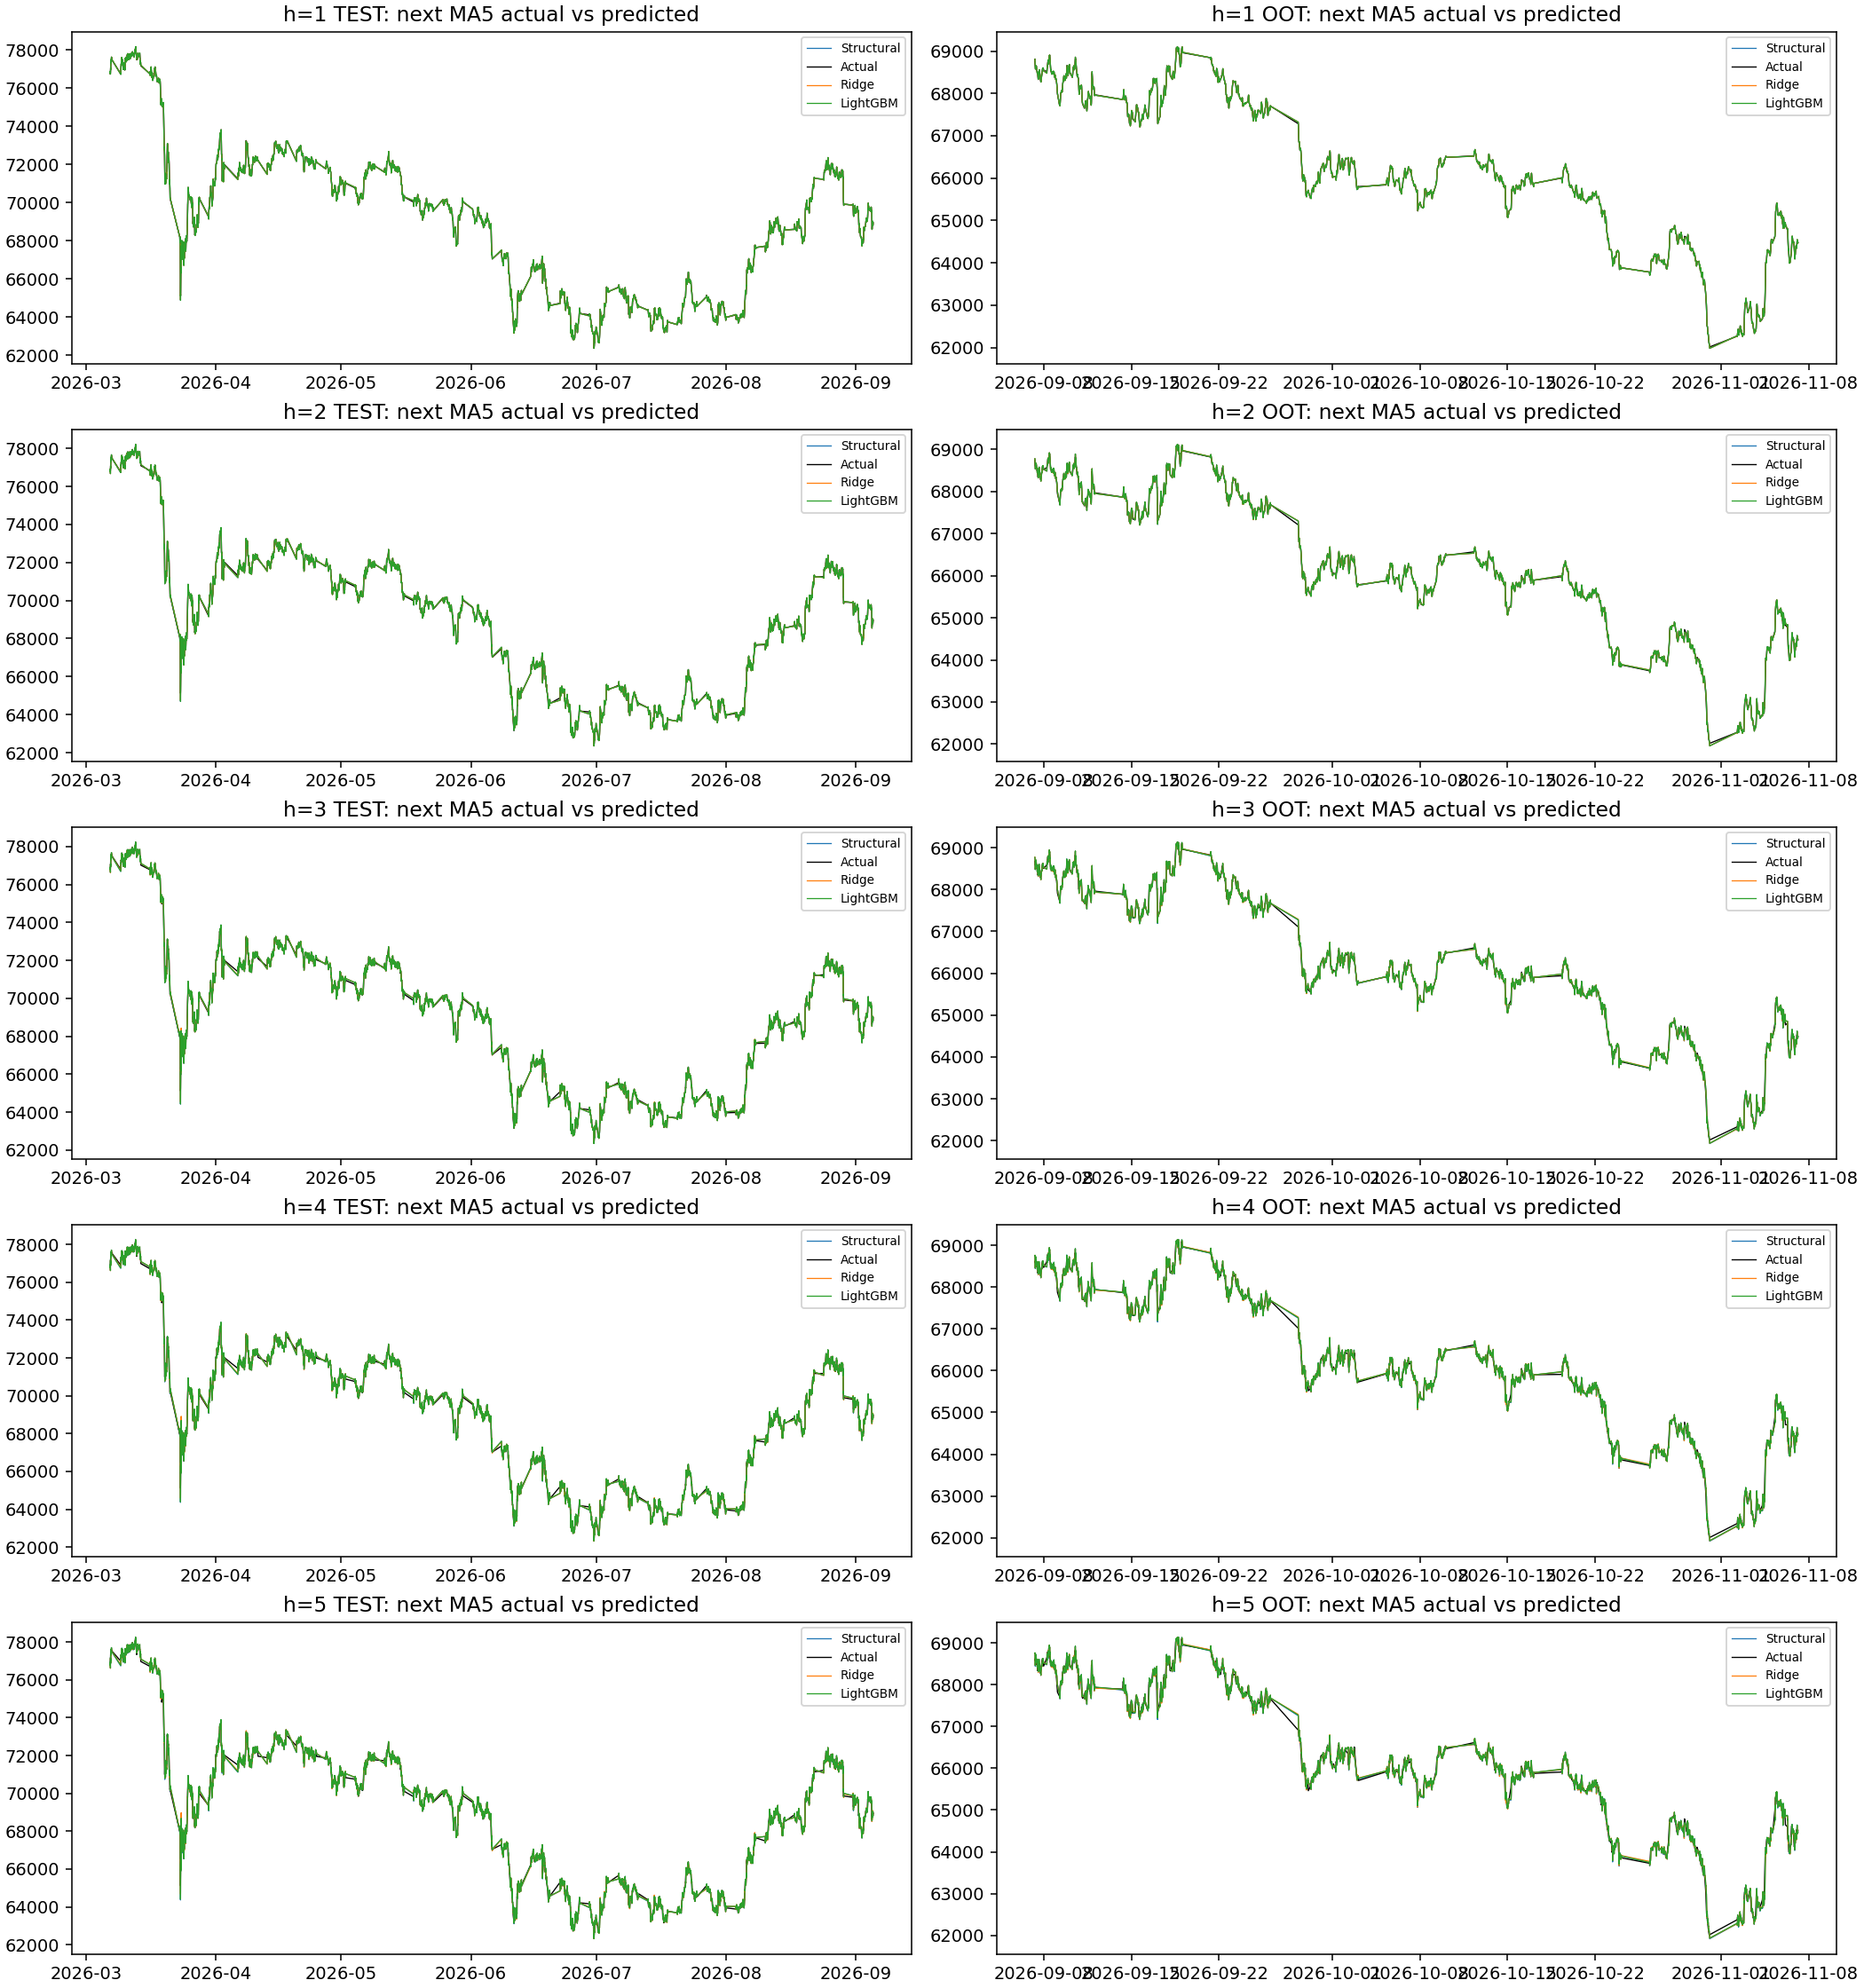

In [6]:
display(Image(filename=str(P/'Price_actual_vs_prediction.png')))

## Interpretation
The 3-feature gain check is a diagnostic. It does not establish predictive improvement. The final two months were already inspected in earlier research, so OOT is chronological but not pristine. Compare price RMSE and directional accuracy with structural persistence, and confirm any improvement on future unseen data.